# UK Online Retail: sales trends and customer segmentation

**Question:** When does this UK online gift retailer make its money, which products drive it, and which customers should it focus on keeping?

**Data:** [UCI Online Retail II](https://archive.ics.uci.edu/dataset/502/online+retail+ii), every transaction of a UK-based online gift wholesaler, Dec 2009 to Dec 2011 (1,067,371 rows). Cleaned with `scripts/01_clean.py`; SQL analysis in `sql/analysis_queries.sql`.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

plt.rcParams.update({"figure.dpi": 120, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
BLUE, RED, GREY = "#1f4e79", "#c0392b", "#b0b7bf"
def title(fig, text): fig.suptitle(text, x=0.01, ha="left", fontweight="bold", fontsize=11)

df = pd.read_csv("../data/retail_clean.csv.gz", parse_dates=["invoice_date"])
print(f"{len(df):,} clean invoice lines, {df['invoice'].nunique():,} orders, {df['customer_id'].nunique():,} known customers")

997,238 clean invoice lines, 39,251 orders, 5,839 known customers


## 1. Cleaning: what was removed and why

In [2]:
pd.read_csv("../data/cleaning_log.csv")

,step,rows
0,Raw rows (both sheets),1067371
1,After removing exact duplicates,1033036
2,After removing cancellations (invoice starts w...,1013932
3,After removing orders that were later cancelled,1007600
4,After removing zero/negative quantity or price,1001582
5,"After removing postage, fees and manual adjust...",997238
6,Rows with a customer ID (used for customer ana...,770400


Key cleaning decisions:
- **Cancellations** (invoice numbers starting with `C`) were removed, **and so were the original orders they cancelled**. Otherwise mistaken bulk orders (e.g. 80,995 units of one paper craft item, cancelled minutes later) would top the product ranking.
- **Postage, bank charges and manual adjustments** are not products, so they were excluded.
- About 23% of lines have no customer ID. They count towards revenue but not the customer analysis.

## 2. When does the business make its money?

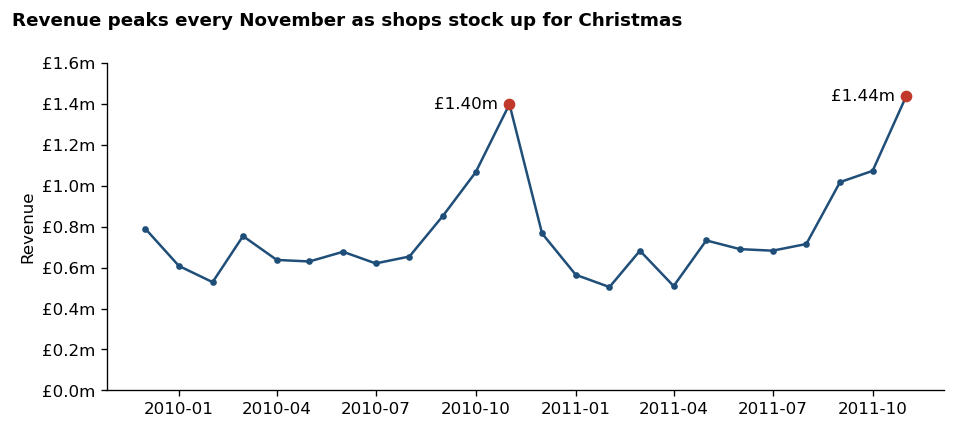

Sep-Nov share of 2010 revenue: 36.1%
Jan-Nov 2011 vs 2010 revenue growth: 2.2%


In [3]:
m = pd.read_csv("../data/monthly_sales.csv")
m["date"] = pd.to_datetime(m["month"])
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(m["date"], m["revenue_gbp"] / 1e6, color=BLUE, marker="o", ms=3)
peaks = m[m["month"].isin(["2010-11", "2011-11"])]
ax.scatter(peaks["date"], peaks["revenue_gbp"] / 1e6, color=RED, zorder=3)
for _, r in peaks.iterrows(): ax.annotate(f"£{r.revenue_gbp/1e6:.2f}m", (r.date, r.revenue_gbp / 1e6), xytext=(-45, 0), textcoords="offset points", va="center")
ax.yaxis.set_major_formatter(mtick.FormatStrFormatter("£%.1fm"))
ax.set(ylabel="Revenue", ylim=(0, 1.6))
title(fig, "Revenue peaks every November as shops stock up for Christmas")
plt.tight_layout(); plt.savefig("../images/01_monthly_revenue.png"); plt.show()

y2010 = m[m["month"].str.startswith("2010")]
q4_share = y2010[y2010["month"].isin(["2010-09", "2010-10", "2010-11"])]["revenue_gbp"].sum() / y2010["revenue_gbp"].sum()
print(f"Sep-Nov share of 2010 revenue: {q4_share:.1%}")
print(f"Jan-Nov 2011 vs 2010 revenue growth: {m[m.month.between('2011-01','2011-11')].revenue_gbp.sum() / m[m.month.between('2010-01','2010-11')].revenue_gbp.sum() - 1:.1%}")

## 3. Which products drive revenue?

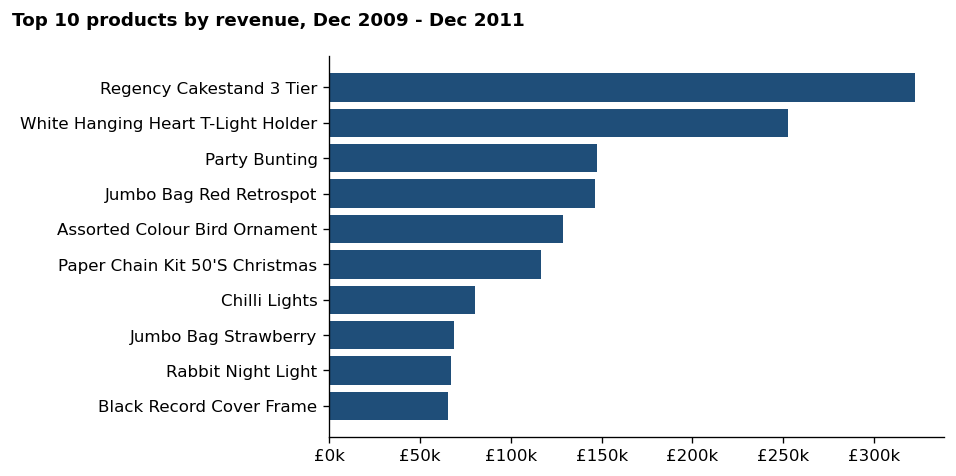

Top 10 products = 7.3% of revenue, out of 5,331 products


In [4]:
p = pd.read_csv("../data/top_products.csv").sort_values("revenue_gbp")
fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(p["description"].str.title(), p["revenue_gbp"] / 1e3, color=BLUE)
ax.xaxis.set_major_formatter(mtick.FormatStrFormatter("£%.0fk"))
title(fig, "Top 10 products by revenue, Dec 2009 - Dec 2011")
plt.tight_layout(); plt.savefig("../images/02_top_products.png"); plt.show()
top10_share = p["revenue_gbp"].sum() / df["revenue"].sum()
print(f"Top 10 products = {top10_share:.1%} of revenue, out of {df['description'].nunique():,} products")

## 4. Who are the customers? RFM segmentation

Each customer gets a 1-5 score for **Recency** (days since last order), **Frequency** (number of orders) and **Monetary** value (total spend), using `NTILE(5)` in SQL. Scores are combined into five segments.

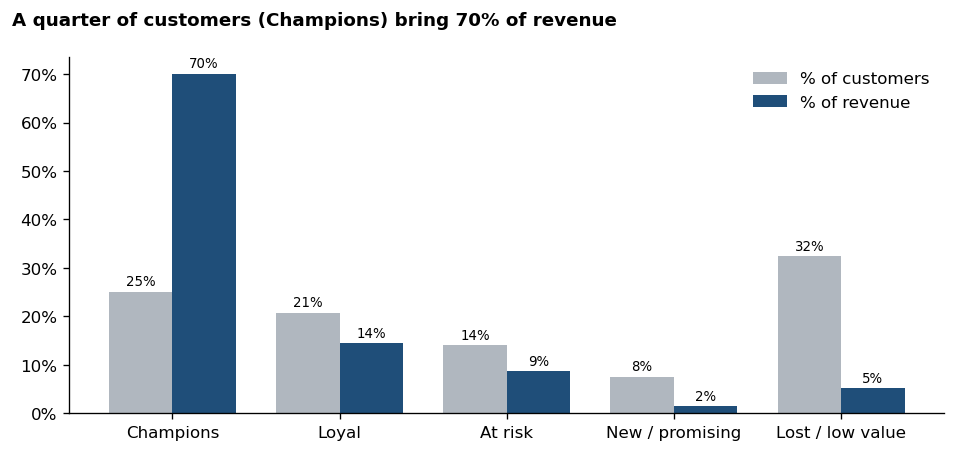

,customers,pct_customers,revenue_gbp,pct_revenue,avg_spend_gbp,avg_days_since_last_order
segment,,,,,,
Champions,1464,25.1,11550509.0,70.1,7890.0,20
Loyal,1215,20.8,2394745.0,14.5,1971.0,78
At risk,824,14.1,1429672.0,8.7,1735.0,369
New / promising,444,7.6,241596.0,1.5,544.0,27
Lost / low value,1892,32.4,850553.0,5.2,450.0,385


In [5]:
s = pd.read_csv("../data/segment_summary.csv").set_index("segment").loc[["Champions", "Loyal", "At risk", "New / promising", "Lost / low value"]]
fig, ax = plt.subplots(figsize=(8, 3.8))
x = range(len(s)); w = 0.38
b1 = ax.bar([i - w/2 for i in x], s["pct_customers"], w, color=GREY, label="% of customers")
b2 = ax.bar([i + w/2 for i in x], s["pct_revenue"], w, color=BLUE, label="% of revenue")
ax.bar_label(b1, fmt="%.0f%%", padding=2, fontsize=8); ax.bar_label(b2, fmt="%.0f%%", padding=2, fontsize=8)
ax.set_xticks(list(x), s.index); ax.yaxis.set_major_formatter(mtick.PercentFormatter()); ax.legend(frameon=False)
title(fig, "A quarter of customers (Champions) bring 70% of revenue")
plt.tight_layout(); plt.savefig("../images/03_rfm_segments.png"); plt.show()
s

In [6]:
rfm = pd.read_csv("../data/customer_rfm.csv")
at_risk = rfm[rfm["segment"] == "At risk"]
print(f"At-risk customers: {len(at_risk):,}, lifetime spend £{at_risk['monetary_gbp'].sum():,.0f}, "
      f"median {at_risk['recency_days'].median():.0f} days since last order")
spend = rfm.sort_values("monetary_gbp", ascending=False)["monetary_gbp"]
print(f"Top 20% of customers = {spend.head(round(len(spend) * 0.2)).sum() / spend.sum():.1%} of customer revenue")

At-risk customers: 824, lifetime spend £1,429,672, median 374 days since last order
Top 20% of customers = 76.7% of customer revenue


## 5. Where are the customers?

In [7]:
c = pd.read_csv("../data/country_sales.csv")
print(f"UK share of revenue: {c.loc[c.country=='United Kingdom','pct_of_revenue'].iat[0]}%, {len(c)} countries in total")
c.head(6)

UK share of revenue: 85.4%, 43 countries in total


,country,revenue_gbp,pct_of_revenue,customers
0,United Kingdom,16267975.0,85.4,5326
1,EIRE,606337.0,3.2,3
2,Netherlands,546263.0,2.9,22
3,Germany,379977.0,2.0,107
4,France,296034.0,1.6,93
5,Australia,166770.0,0.9,15


## Key findings

1. **Strong seasonality:** September to November brought 36.1% of 2010 revenue, and November is the peak month in both years (£1.40m in 2010, £1.44m in 2011). Revenue grew only 2.2% from Jan-Nov 2010 to Jan-Nov 2011.
2. **A long tail of products:** the top 10 products (led by the Regency Cakestand, £323k) make up just 7.3% of revenue across 5,331 products.
3. **Revenue depends on a few customers:** the top 20% of customers bring about 77% of revenue. The *Champions* segment is 25% of customers but 70% of revenue.
4. **£1.43m at risk:** 824 previously frequent customers (*At risk*) have not ordered for about a year on average (369 days).
5. **Mostly UK, closed on Saturdays:** 85.4% of revenue comes from the UK across 43 countries. Almost no orders are placed on Saturdays (30 in two years).

**Recommendations**
- Plan stock, staffing and marketing around the September-November peak, and start Christmas campaigns in August.
- Run a win-back campaign for the 824 *At risk* customers, who spent £1,735 each on average.
- Protect the *Champions*: a loyalty or account-manager programme for the top 1,464 customers would safeguard 70% of revenue.
